In [1]:

# =============================================================================
# NOTEBOOK 3: UNCERTAINTY QUANTIFICATION & PROBABILITY CALIBRATION
# ISIC 2019 — MC-Dropout + Temperature Scaling
# =============================================================================
# PURPOSE : Teach the ensemble to know when it is guessing.
#           Two complementary techniques:
#
#   A. TEMPERATURE SCALING (Calibration)
#      The binary models currently output overconfident probabilities
#      (e.g., 0.99 when the true frequency is 0.75).  We fit a single
#      temperature parameter T on the validation logits so that the
#      calibrated probability reflects real-world reliability.
#      Evaluation: Expected Calibration Error (ECE) before vs after.
#
#   B. MONTE CARLO DROPOUT (UQ)
#      Keep Dropout active at inference time.  Run each test image
#      through the ensemble N=30 times.  The variance of predictions
#      is our Uncertainty Score (epistemic uncertainty estimate).
#      Images with high variance are flagged for manual review.
#
# INPUTS  : Trained model weights (all three binary models)
#           binary_val.csv, binary_test.csv
#
# OUTPUTS : /kaggle/working/uq_outputs/
#               temperature_params.json       ← T per model
#               calibrated_predictions.csv    ← calibrated prob + uncertainty
#               calibration_curves.png
#               uncertainty_distribution.png
#               reliability_diagram.png
# =============================================================================



In [2]:
import os, gc, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm

from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore')
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

Device: cuda


In [3]:
INPUT_CSV_DIR   = '/kaggle/input/notebooks/nandini143/data-preparation'
MODEL_DIR       = '/kaggle/input/notebooks/nandini143'
OUTPUT_DIR      = '/kaggle/working/xai_outputs'
MODEL_NAME      = 'swin_tiny_patch4_window7_224'

DENSENET_CKPT   = '/kaggle/input/notebooks/nandini143/binary-densenet-121/densenet121_best.pth'
EFFNET_CKPT     = '/kaggle/input/notebooks/nandini143/binary-efficientnetv2s/efficientnetv2s_best.pth'
SWIN_CKPT       = '/kaggle/input/notebooks/nandini143/binary-swin-tiny-transformer/swin_tiny_best.pth'
CONVNEXT_CKPT   = '/kaggle/input/notebooks/nandini143/binary-convnext/convnext_tiny_best.pth'
RESNET_CKPT     = '/kaggle/input/notebooks/nandini143/binary-resnet-200d/resnet200d_best.pth'

IMG_SIZE_CNN  = 384
IMG_SIZE_SWIN = 224
BATCH_SIZE    = 32
MC_RUNS       = 30      # Number of stochastic forward passes for MC-Dropout

OLD_PATH      = '/kaggle/working/preprocessed/'
NEW_PATH      = f'{INPUT_CSV_DIR}/preprocessed/'
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
ECE_BINS      = 15      # Number of bins for Expected Calibration Error

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Output dir ready:", OUTPUT_DIR)

# ── Early META_COLS detection (required before Cell 3 builders) ──────────
import pandas as pd
_meta_probe = pd.read_csv(f'{INPUT_CSV_DIR}/binary_val.csv', nrows=1)
META_COLS = (['age_norm', 'sex_male', 'sex_female'] + 
             [c for c in _meta_probe.columns if c.startswith('site_')])
print(f'META_COLS detected ({len(META_COLS)}): {META_COLS}')
del _meta_probe

Output dir ready: /kaggle/working/xai_outputs
META_COLS detected (12): ['age_norm', 'sex_male', 'sex_female', 'site_oral_genital', 'site_posterior_torso', 'site_unknown', 'site_head_neck', 'site_lower_extremity', 'site_lateral_torso', 'site_palms_soles', 'site_upper_extremity', 'site_anterior_torso']


In [4]:
import torch
import torch.nn as nn
import timm

class TabularMLP(nn.Module):
    def __init__(self, in_dim, hidden_dim=32, out_dim=32, dropout=0.4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.BatchNorm1d(hidden_dim), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, out_dim), nn.GELU()
        )
    def forward(self, x): return self.net(x)

# ── Binary Models ─────────────────────────────────────────────────────────────
class MultiModalSwin(nn.Module):
    def __init__(self, meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model(
            'swin_tiny_patch4_window7_224', pretrained=pretrained, 
            num_classes=0, drop_path_rate=0.2)
        feat_dim = self.backbone.num_features
        self.meta_mlp = TabularMLP(meta_dim, 32, 32, 0.4)
        self.head = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(feat_dim + 32, 256),
            nn.BatchNorm1d(256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1))
    def forward(self, x, meta=None):
        f = self.backbone(x)
        if len(f.shape) == 3: f = f.mean(dim=1)
        m = meta if meta is not None else torch.zeros(x.size(0), self.meta_dim, device=x.device)
        return self.head(torch.cat([f, self.meta_mlp(m)], dim=1))

class MultiModalDenseNet(nn.Module):
    def __init__(self, meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model(
            'densenet121', pretrained=pretrained, num_classes=0, global_pool='avg')
        feat_dim = self.backbone.num_features
        self.meta_mlp = TabularMLP(meta_dim, 32, 32, 0.4)
        self.head = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(feat_dim + 32, 256),
            nn.BatchNorm1d(256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1))
    def forward(self, x, meta=None):
        f = self.backbone(x)
        m = meta if meta is not None else torch.zeros(x.size(0), self.meta_dim, device=x.device)
        return self.head(torch.cat([f, self.meta_mlp(m)], dim=1))

class MultiModalEfficientNet(nn.Module):
    def __init__(self, meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model(
            'tf_efficientnetv2_s', pretrained=pretrained, num_classes=0, 
            global_pool='avg', drop_path_rate=0.2)
        feat_dim = self.backbone.num_features
        self.meta_mlp = TabularMLP(meta_dim, 32, 32, 0.4)
        self.head = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(feat_dim + 32, 256),
            nn.BatchNorm1d(256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1))
    def forward(self, x, meta=None):
        f = self.backbone(x)
        m = meta if meta is not None else torch.zeros(x.size(0), self.meta_dim, device=x.device)
        return self.head(torch.cat([f, self.meta_mlp(m)], dim=1))

class MultiModalConvNeXt(nn.Module):
    def __init__(self, meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model(
            'convnext_tiny', pretrained=pretrained, num_classes=0)
        feat_dim = self.backbone.num_features
        self.meta_mlp = TabularMLP(meta_dim, 32, 32, 0.4)
        self.head = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(feat_dim + 32, 256),
            nn.BatchNorm1d(256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1))
    def forward(self, x, meta=None):
        f = self.backbone(x)
        m = meta if meta is not None else torch.zeros(x.size(0), self.meta_dim, device=x.device)
        return self.head(torch.cat([f, self.meta_mlp(m)], dim=1))

class MultiModalResNet(nn.Module):
    def __init__(self, meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model(
            'resnet200d', pretrained=pretrained, num_classes=0)
        feat_dim = self.backbone.num_features
        self.meta_branch = nn.Sequential(
            nn.Linear(meta_dim, 64), nn.BatchNorm1d(64), nn.SiLU(),
            nn.Dropout(0.2), nn.Linear(64, 32), nn.BatchNorm1d(32), nn.SiLU())
        self.head = nn.Sequential(
            nn.Linear(feat_dim + 32, 256), nn.BatchNorm1d(256), nn.SiLU(),
            nn.Dropout(0.4), nn.Linear(256, 1))
    def forward(self, x, meta=None):
        f = self.backbone(x)
        m = meta if meta is not None else torch.zeros(x.size(0), self.meta_dim, device=x.device)
        return self.head(torch.cat([f, self.meta_branch(m)], dim=1))

def build_swin_tiny(meta_dim=9, pretrained=False):     return MultiModalSwin(meta_dim=meta_dim, pretrained=pretrained)
def build_densenet121(meta_dim=9, pretrained=False):   return MultiModalDenseNet(meta_dim=meta_dim, pretrained=pretrained)
def build_efficientnetv2s(meta_dim=9, pretrained=False): return MultiModalEfficientNet(meta_dim=meta_dim, pretrained=pretrained)
def build_convnext_tiny(meta_dim=9, pretrained=False): return MultiModalConvNeXt(meta_dim=meta_dim, pretrained=pretrained)
def build_resnet200d(meta_dim=9, pretrained=False):    return MultiModalResNet(meta_dim=meta_dim, pretrained=pretrained)

def _get_meta_dim_from_checkpoint(state_dict):
    w = state_dict.get('meta_mlp.net.0.weight', None)
    if w is not None: return w.shape[1]
    w = state_dict.get('meta_branch.0.weight', None)
    if w is not None: return w.shape[1]
    print("  [WARNING] Could not detect meta_dim from checkpoint. Falling back to len(META_COLS).")
    return len(META_COLS)

def load_model(builder_fn, ckpt_path, device):
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    state = ckpt.get('model_state_dict', ckpt.get('model_state', ckpt))
    detected_dim = _get_meta_dim_from_checkpoint(state)
    model = builder_fn(meta_dim=detected_dim)
    model.load_state_dict(state, strict=True)
    print(f"    meta_dim={detected_dim} (auto-detected from checkpoint)")
    return model.to(device).eval()

In [5]:
class BinaryDataset(Dataset):
    def __init__(self, df, transform, meta_cols):
        self.df = df.reset_index(drop=True)
        self.tf = transform
        self.meta_cols = meta_cols

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        img   = Image.open(row['image_path']).convert('RGB')
        label = torch.tensor(row['binary_label'], dtype=torch.float32)
        
        # Dynamically extract patient metadata
        meta_vals = [float(row.get(c, 0.0)) for c in self.meta_cols]
        meta = torch.tensor(meta_vals, dtype=torch.float32)
        
        return self.tf(img), meta, label, str(row.get('image_id', idx))

def get_meta_cols(df):
    base_meta = ['age_norm', 'sex_male', 'sex_female']
    site_cols = [c for c in df.columns if c.startswith('site_')]
    return base_meta + site_cols

def make_loader(df, img_size, meta_cols, batch_size=BATCH_SIZE):
    tf = T.Compose([T.Resize((img_size, img_size)), T.ToTensor(),
                    T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
    ds = BinaryDataset(df, tf, meta_cols)
    return DataLoader(ds, batch_size=batch_size, shuffle=False,
                      num_workers=2, pin_memory=True)

val_df  = pd.read_csv(f'{INPUT_CSV_DIR}/binary_val.csv')
test_df = pd.read_csv(f'{INPUT_CSV_DIR}/binary_test.csv')

for d in [val_df, test_df]:
    d['image_path'] = d['image_path'].str.replace(OLD_PATH, NEW_PATH, regex=False)

META_COLS = get_meta_cols(val_df)
print(f"Val: {len(val_df)} | Test: {len(test_df)}")
print(f"Metadata features detected ({len(META_COLS)}): {META_COLS}")

Val: 2533 | Test: 2534
Metadata features detected (12): ['age_norm', 'sex_male', 'sex_female', 'site_oral_genital', 'site_posterior_torso', 'site_unknown', 'site_head_neck', 'site_lower_extremity', 'site_lateral_torso', 'site_palms_soles', 'site_upper_extremity', 'site_anterior_torso']


In [6]:
from scipy.optimize import minimize_scalar
from sklearn.metrics import log_loss

class TemperatureScaler:
    def __init__(self):
        self.temperature = 1.0

    def fit(self, model: nn.Module, val_loader: DataLoader, device):
        logits_list, labels_list = [], []

        with torch.no_grad():
            for imgs, meta, labels, _ in tqdm(val_loader, desc="  Collecting logits"):
                imgs = imgs.to(device)
                meta = meta.to(device)
                
                # --- FIX: Match meta dimensions with model.meta_dim ---
                if hasattr(model, 'meta_dim'):
                    if meta.shape[1] > model.meta_dim:
                        meta = meta[:, :model.meta_dim]
                    elif meta.shape[1] < model.meta_dim:
                        meta = F.pad(meta, (0, model.meta_dim - meta.shape[1]))
                
                logits = model(imgs, meta).view(-1) 
                logits_list.append(logits.cpu().numpy())
                labels_list.append(labels.view(-1).numpy())

        all_logits = np.concatenate(logits_list)
        all_labels = np.concatenate(labels_list)

        def eval_loss(t):
            scaled_logits = all_logits / t
            probs = 1.0 / (1.0 + np.exp(-scaled_logits))
            probs = np.clip(probs, 1e-15, 1 - 1e-15)
            return log_loss(all_labels, probs)

        res = minimize_scalar(eval_loss, bounds=(0.1, 5.0), method='bounded')
        self.temperature = res.x
        
        print(f"  Optimal Temperature T = {self.temperature:.4f}")
        return self.temperature

In [7]:
def compute_ece(probs: np.ndarray, labels: np.ndarray, n_bins: int = ECE_BINS) -> float:
    probs = np.array(probs).flatten()
    labels = np.array(labels).flatten()
    
    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        mask = (probs >= lo) & (probs < hi)
        if np.sum(mask) == 0:
            continue
        acc_bin = labels[mask].mean()
        conf_bin = probs[mask].mean()
        ece += np.sum(mask) * abs(acc_bin - conf_bin)
    return ece / len(probs)

In [8]:
print("\n" + "="*60)
print("  PART A — Temperature Scaling Calibration")
print("="*60)

model_configs = [
    ('Swin-Tiny',         build_swin_tiny,       SWIN_CKPT,     IMG_SIZE_SWIN),
    ('DenseNet-121',      build_densenet121,     DENSENET_CKPT, IMG_SIZE_CNN),
    ('EfficientNetV2-S',  build_efficientnetv2s, EFFNET_CKPT,   IMG_SIZE_CNN),
    ('ConvNeXt-Tiny',     build_convnext_tiny,   CONVNEXT_CKPT, IMG_SIZE_CNN),
    ('ResNet-200D',       build_resnet200d,      RESNET_CKPT,   IMG_SIZE_SWIN),
]

temp_params = {}
raw_probs_store = {}

for model_name, builder, ckpt, img_sz in model_configs:
    print(f"\n  [{model_name}]")
    model   = load_model(builder, ckpt, DEVICE)
    val_ld  = make_loader(val_df, img_sz, META_COLS)
    test_ld = make_loader(test_df, img_sz, META_COLS)

    raw_logits, raw_labels = [], []
    with torch.no_grad():
        for imgs, meta, labels, _ in tqdm(val_ld, desc="  Val logits", leave=False):
            imgs = imgs.to(DEVICE)
            meta = meta.to(DEVICE)
            
            # --- FIX: Match meta dimensions with model.meta_dim ---
            if hasattr(model, 'meta_dim'):
                if meta.shape[1] > model.meta_dim:
                    meta = meta[:, :model.meta_dim]
                elif meta.shape[1] < model.meta_dim:
                    meta = F.pad(meta, (0, model.meta_dim - meta.shape[1]))
            
            out = model(imgs, meta)
            logits = out.view(-1).cpu() 
            raw_logits.append(logits)
            raw_labels.append(labels.view(-1))
            
    raw_logits = torch.cat(raw_logits)
    raw_labels = torch.cat(raw_labels)

    if raw_logits.shape[0] != raw_labels.shape[0]:
        min_len = min(raw_logits.shape[0], raw_labels.shape[0])
        raw_logits = raw_logits[:min_len]
        raw_labels = raw_labels[:min_len]

    raw_probs  = torch.sigmoid(raw_logits).numpy()
    lbl_np     = raw_labels.numpy()
    
    valid_mask = lbl_np != -1
    raw_probs = raw_probs[valid_mask]
    lbl_np = lbl_np[valid_mask]

    ece_before = compute_ece(raw_probs, lbl_np)
    brier_before = brier_score_loss(lbl_np, raw_probs)

    scaler  = TemperatureScaler()
    T_val   = scaler.fit(model, val_ld, DEVICE)
    cal_probs = torch.sigmoid(raw_logits / scaler.temperature).detach().numpy()
    cal_probs = cal_probs[valid_mask]
    ece_after  = compute_ece(cal_probs, lbl_np)
    brier_after = brier_score_loss(lbl_np, cal_probs)

    print(f"  ECE   Before: {ece_before:.4f}  →  After: {ece_after:.4f}")
    print(f"  Brier Before: {brier_before:.4f}  →  After: {brier_after:.4f}")

    temp_params[model_name] = {
        'temperature'  : float(T_val),
        'ece_before'   : float(ece_before),
        'ece_after'    : float(ece_after),
        'brier_before' : float(brier_before),
        'brier_after'  : float(brier_after),
    }
    raw_probs_store[model_name] = {'raw': raw_probs, 'cal': cal_probs, 'labels': lbl_np}
    del model; gc.collect(); torch.cuda.empty_cache()

with open(os.path.join(OUTPUT_DIR, 'temperature_params.json'), 'w') as f:
    json.dump(temp_params, f, indent=2)

print("\nTemperature params saved.")


  PART A — Temperature Scaling Calibration

  [Swin-Tiny]
    meta_dim=11 (auto-detected from checkpoint)


  Optimal Temperature T = 0.6776
  ECE   Before: 0.0720  →  After: 0.0435
  Brier Before: 0.0864  →  After: 0.0833

  [DenseNet-121]
    meta_dim=11 (auto-detected from checkpoint)


  Optimal Temperature T = 0.4968
  ECE   Before: 0.1056  →  After: 0.0331
  Brier Before: 0.1096  →  After: 0.0980

  [EfficientNetV2-S]
    meta_dim=11 (auto-detected from checkpoint)


  Optimal Temperature T = 0.6830
  ECE   Before: 0.0527  →  After: 0.0103
  Brier Before: 0.0694  →  After: 0.0658

  [ConvNeXt-Tiny]
    meta_dim=11 (auto-detected from checkpoint)


  Optimal Temperature T = 0.6064
  ECE   Before: 0.0781  →  After: 0.0200
  Brier Before: 0.0813  →  After: 0.0754

  [ResNet-200D]
    meta_dim=11 (auto-detected from checkpoint)


  Optimal Temperature T = 0.6413
  ECE   Before: 0.0905  →  After: 0.0593
  Brier Before: 0.0914  →  After: 0.0868

Temperature params saved.


In [9]:
print("\n" + "="*60)
print("  PART B — Monte Carlo Dropout Uncertainty Estimation")
print("="*60)

def enable_mc_dropout(model: nn.Module):
    for m in model.modules():
        if isinstance(m, nn.Dropout) or 'Drop' in type(m).__name__:
            m.train()

def mc_dropout_inference(model: nn.Module, img_tensor: torch.Tensor, meta_tensor: torch.Tensor,
                          n_runs: int = MC_RUNS, temperature: float = 1.0, 
                          device=DEVICE) -> dict:
    enable_mc_dropout(model)
    preds = []
    imgs  = img_tensor.to(device)
    meta  = meta_tensor.to(device)
    
    # --- FIX: Match meta dimensions with model.meta_dim ---
    if hasattr(model, 'meta_dim'):
        if meta.shape[1] > model.meta_dim:
            meta = meta[:, :model.meta_dim]
        elif meta.shape[1] < model.meta_dim:
            meta = F.pad(meta, (0, model.meta_dim - meta.shape[1]))
            
    for _ in range(n_runs):
        with torch.no_grad():
            logits = model(imgs, meta)
            logits = logits.view(-1) 
            prob  = torch.sigmoid(logits / temperature).cpu().numpy()
        preds.append(prob)
        
    preds = np.array(preds)
    return {
        'mean'         : preds.mean(axis=0),
        'variance'     : preds.var(axis=0),
        'std'          : preds.std(axis=0),
        'ci95_lo'      : np.percentile(preds, 2.5, axis=0),
        'ci95_hi'      : np.percentile(preds, 97.5, axis=0),
    }

print("  Running MC-Dropout on test set …")
test_ld_cnn  = make_loader(test_df, IMG_SIZE_CNN, META_COLS, batch_size=BATCH_SIZE)
test_ld_swin = make_loader(test_df, IMG_SIZE_SWIN, META_COLS, batch_size=BATCH_SIZE)

loaders = {
    'DenseNet-121'     : test_ld_cnn,
    'EfficientNetV2-S' : test_ld_cnn,
    'ConvNeXt-Tiny'    : test_ld_cnn,
    'Swin-Tiny'        : test_ld_swin,
    'ResNet-200D'      : test_ld_swin,
}

test_ids = test_df.get('image_id', test_df.index).astype(str).tolist()
result_rows = {iid: {} for iid in test_ids}

for model_name, builder, ckpt, img_sz in model_configs:
    print(f"\n  [{model_name}] — {MC_RUNS} MC passes")
    model  = load_model(builder, ckpt, DEVICE)
    T_val  = temp_params.get(model_name, {}).get('temperature', 1.0)
    loader = loaders[model_name]

    for imgs, meta, labels, img_ids in tqdm(loader, desc=f"  {model_name} MC"):
        mc_out = mc_dropout_inference(model, imgs, meta, MC_RUNS, T_val, DEVICE)
        
        for j, iid in enumerate(img_ids):
            if iid not in result_rows:
                result_rows[iid] = {}
            
            result_rows[iid].update({
                f'{model_name}_mean'     : float(mc_out['mean'][j]),
                f'{model_name}_variance' : float(mc_out['variance'][j]),
                f'{model_name}_ci95_lo'  : float(mc_out['ci95_lo'][j]),
                f'{model_name}_ci95_hi'  : float(mc_out['ci95_hi'][j]),
                'true_label'             : int(labels[j].item()),
                'image_id'               : iid
            })

    del model; gc.collect(); torch.cuda.empty_cache()


  PART B — Monte Carlo Dropout Uncertainty Estimation
  Running MC-Dropout on test set …

  [Swin-Tiny] — 30 MC passes
    meta_dim=11 (auto-detected from checkpoint)


  Swin-Tiny MC: 100%|██████████| 80/80 [07:07<00:00,  5.34s/it]



  [DenseNet-121] — 30 MC passes
    meta_dim=11 (auto-detected from checkpoint)


  DenseNet-121 MC: 100%|██████████| 80/80 [11:42<00:00,  8.78s/it]



  [EfficientNetV2-S] — 30 MC passes
    meta_dim=11 (auto-detected from checkpoint)


  EfficientNetV2-S MC: 100%|██████████| 80/80 [13:39<00:00, 10.25s/it]



  [ConvNeXt-Tiny] — 30 MC passes
    meta_dim=11 (auto-detected from checkpoint)


  ConvNeXt-Tiny MC: 100%|██████████| 80/80 [17:39<00:00, 13.24s/it]



  [ResNet-200D] — 30 MC passes
    meta_dim=11 (auto-detected from checkpoint)


  ResNet-200D MC: 100%|██████████| 80/80 [14:59<00:00, 11.25s/it]


In [10]:
print("\nAggregating ensemble uncertainty …")
rows_out = []

# First pass: collect all ensemble variances
all_vars = []
for iid, d in result_rows.items():
    if 'image_id' not in d: continue
    vars_ = [d.get(f'{nm}_variance', np.nan) for nm, *_ in model_configs]
    all_vars.append(float(np.nanmean(vars_)))

# Calculate dynamic threshold (95th percentile)
if all_vars:
    dynamic_threshold = float(np.percentile(all_vars, 95))
    print(f"Dynamic Uncertainty Threshold (95th Percentile) set to: {dynamic_threshold:.5f}")
else:
    dynamic_threshold = 0.005 # fallback

# Save the dynamic threshold to a json file so Notebook 4 can use it!
import json
with open(os.path.join(OUTPUT_DIR, 'dynamic_threshold.json'), 'w') as f:
    json.dump({'UNCERTAINTY_THRESHOLD': dynamic_threshold}, f)

# Second pass: populate rows
for iid, d in result_rows.items():
    if 'image_id' not in d:
        continue
    means = [d.get(f'{nm}_mean', np.nan) for nm, *_ in model_configs]
    vars_ = [d.get(f'{nm}_variance', np.nan) for nm, *_ in model_configs]

    ens_mean      = float(np.nanmean(means))
    ens_variance  = float(np.nanmean(vars_))
    ens_pred      = 1 if ens_mean >= 0.5 else 0
    high_unc      = bool(ens_variance > dynamic_threshold)

    d.update({
        'ensemble_mean_prob' : ens_mean,
        'ensemble_variance'  : ens_variance,
        'ensemble_pred'      : ens_pred,
        'high_uncertainty'   : high_unc,
        'flag_manual_review' : high_unc,
    })
    rows_out.append(d)

uq_df = pd.DataFrame(rows_out)
uq_df.to_csv(os.path.join(OUTPUT_DIR, 'calibrated_predictions.csv'), index=False)
print(f"Saved {len(uq_df)} predictions with uncertainty scores.")



Aggregating ensemble uncertainty …
Dynamic Uncertainty Threshold (95th Percentile) set to: 0.01394
Saved 2534 predictions with uncertainty scores.


In [11]:
flagged = uq_df['flag_manual_review'].sum()
total   = len(uq_df)

labeled_uq = uq_df[uq_df['true_label'] != -1]
auc     = roc_auc_score(labeled_uq['true_label'], labeled_uq['ensemble_mean_prob'])
brier   = brier_score_loss(labeled_uq['true_label'], labeled_uq['ensemble_mean_prob'])

print("\n" + "="*60)
print("  MC-DROPOUT ENSEMBLE — TEST SET SUMMARY")
print("="*60)
print(f"  Total test images       : {total}")
print(f"  AUC-ROC (calibrated)    : {auc:.4f}")
print(f"  Brier Score             : {brier:.4f}  (↓ lower is better)")
print(f"  High-Uncertainty flags  : {flagged} ({flagged/total*100:.1f}%)")
print(f"  (These cases are auto-flagged for dermatologist review)")
print("="*60)


  MC-DROPOUT ENSEMBLE — TEST SET SUMMARY
  Total test images       : 2534
  AUC-ROC (calibrated)    : 0.9696
  Brier Score             : 0.0707  (↓ lower is better)
  High-Uncertainty flags  : 127 (5.0%)
  (These cases are auto-flagged for dermatologist review)


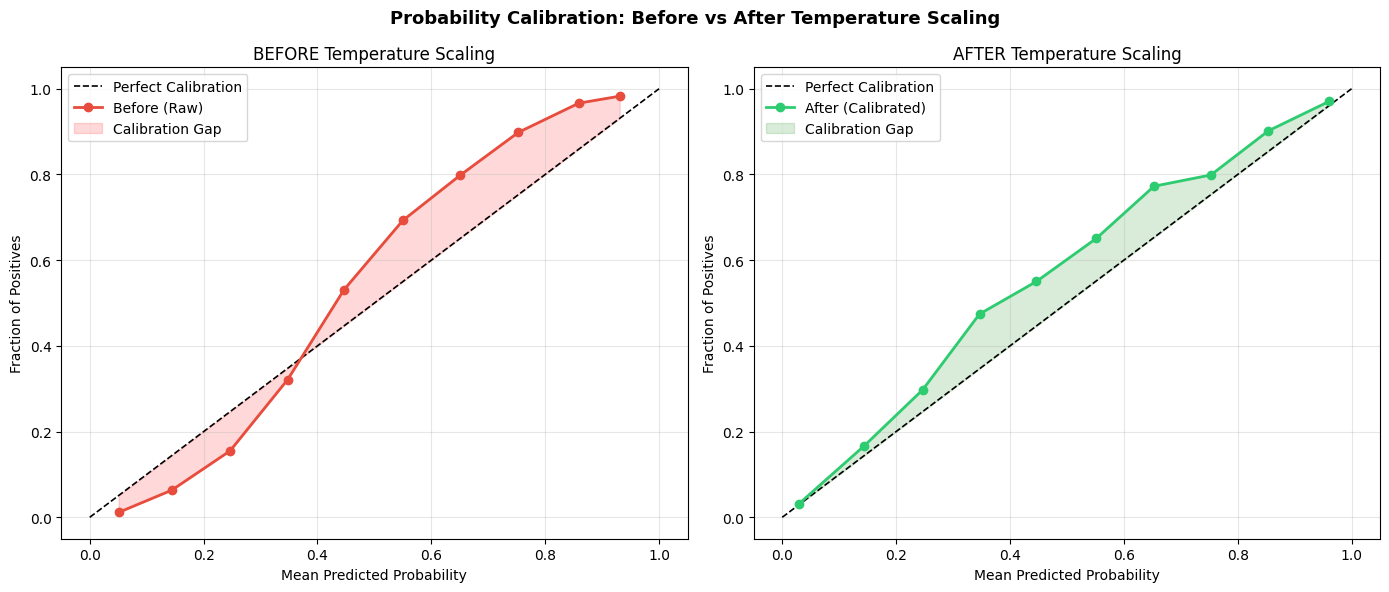

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    "Probability Calibration: Before vs After Temperature Scaling",
    fontsize=13, fontweight='bold')

all_raw = np.concatenate([v['raw'] for v in raw_probs_store.values()])
all_cal = np.concatenate([v['cal'] for v in raw_probs_store.values()])
all_lbl = np.concatenate([v['labels'] for v in raw_probs_store.values()])

frac_pos_raw, mean_pred_raw = calibration_curve(all_lbl, all_raw, n_bins=10)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.2, label='Perfect Calibration')
axes[0].plot(mean_pred_raw, frac_pos_raw, '-o', color='#e74c3c', lw=2, label='Before (Raw)')
axes[0].fill_between(
    mean_pred_raw, frac_pos_raw, mean_pred_raw,
    alpha=0.15, color='red', label='Calibration Gap')
axes[0].set_title("BEFORE Temperature Scaling")
axes[0].set_xlabel("Mean Predicted Probability")
axes[0].set_ylabel("Fraction of Positives")
axes[0].legend()
axes[0].grid(alpha=0.3)

frac_pos_cal, mean_pred_cal = calibration_curve(all_lbl, all_cal, n_bins=10)
axes[1].plot([0, 1], [0, 1], 'k--', lw=1.2, label='Perfect Calibration')
axes[1].plot(mean_pred_cal, frac_pos_cal, '-o', color='#2ecc71', lw=2, label='After (Calibrated)')
axes[1].fill_between(
    mean_pred_cal, frac_pos_cal, mean_pred_cal,
    alpha=0.15, color='green', label='Calibration Gap')
axes[1].set_title("AFTER Temperature Scaling")
axes[1].set_xlabel("Mean Predicted Probability")
axes[1].set_ylabel("Fraction of Positives")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'reliability_diagram.png'), dpi=150, bbox_inches='tight')
plt.show()
plt.close()

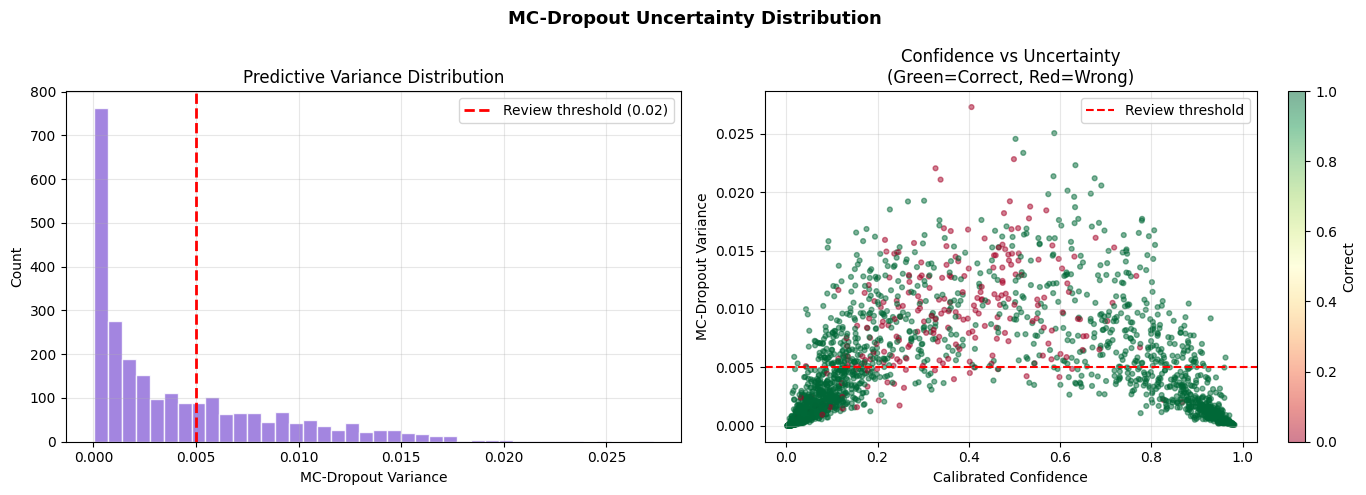


✅ Notebook 3 Complete. Calibration + UQ outputs saved to: /kaggle/working/xai_outputs


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("MC-Dropout Uncertainty Distribution", fontsize=13, fontweight='bold')

axes[0].hist(uq_df['ensemble_variance'], bins=40, color='mediumpurple',
             edgecolor='white', alpha=0.85)
axes[0].axvline(0.005, color='red', ls='--', lw=2, label='Review threshold (0.02)')
axes[0].set_title("Predictive Variance Distribution")
axes[0].set_xlabel("MC-Dropout Variance"); axes[0].set_ylabel("Count")
axes[0].legend(); axes[0].grid(alpha=0.3)

correct_mask = (uq_df['ensemble_pred'] == uq_df['true_label']).values
sc = axes[1].scatter(
    uq_df['ensemble_mean_prob'],
    uq_df['ensemble_variance'],
    c=correct_mask.astype(int),
    cmap='RdYlGn', alpha=0.5, s=12)
axes[1].axhline(0.005, color='red', ls='--', lw=1.5, label='Review threshold')
axes[1].set_title("Confidence vs Uncertainty\n(Green=Correct, Red=Wrong)")
axes[1].set_xlabel("Calibrated Confidence"); axes[1].set_ylabel("MC-Dropout Variance")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.colorbar(sc, ax=axes[1], label='Correct')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'uncertainty_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print("\n✅ Notebook 3 Complete. Calibration + UQ outputs saved to:", OUTPUT_DIR)
plt.close()